# A simple test bench with given By(x)

In [1]:
%pylab

Using matplotlib backend: Qt5Agg
Populating the interactive namespace from numpy and matplotlib


In [2]:
n=41
w=10
x=linspace(-w,w,n)
By=arctan(x)*2.0/pi
figure(figsize=(5,5))
plot(x,By,'-+');

In [3]:
dEzdt=gradient(By,x)
figure(figsize=(5,5))
plot(x,dEzdt,'-+');

In [4]:
x=linspace(-w,w,n)
By=arctan(x)*2.0/pi
dt=0.01
Ez=zeros(n)
Jz=zeros(n)
nt=200
Jz=zeros(n)
jz=[]
ez=[]
tt=[]
t=0.0
figure(figsize=(5,5))
for i in range(nt):
    dEzdt=gradient(By,x)-Jz
    Ez+=dt*dEzdt
    ez.append(Ez[n//2])
    dJzdt=Ez*10
    Jz+=dt*dJzdt
    dBydt=-gradient(Ez,x)
    By+=dt*dBydt
    jz.append(Jz[n//2])
    t += dt
    tt.append(t)
    if i%20==0:
        plot(x,Ez);

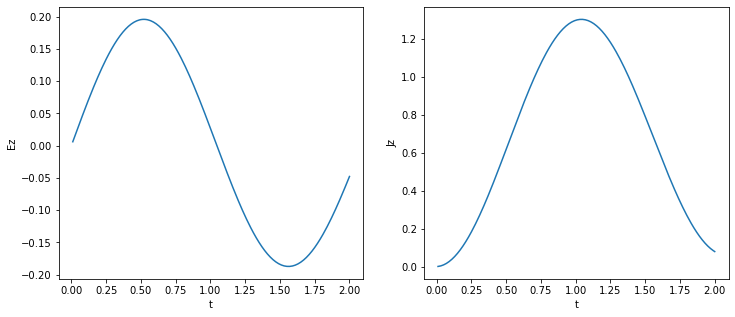

In [76]:
figure(figsize=(12,5))
clf()
subplot(1,2,1)
plot(tt,ez); xlabel('t'); ylabel('Ez')
subplot(1,2,2)
plot(tt,jz); xlabel('t'); ylabel('Jz');

Now place npc particles per cell, in a 2-D pattern, with x and z as coordinates with the same dimensions:

In [77]:
class particles(object):
    def __init__(self,x,z,npc=1,a=1):
        self.nx=len(x)
        self.x=zeros((self.nx,self.nx*npc))
        self.z=zeros((self.nx,self.nx*npc))
        self.vz=zeros((self.nx,self.nx*npc))
        for ix in range(self.nx):
            zz=[]
            for z0 in z:
                zz.extend(z0+a*(random.random(npc)-0.5))
            self.x[ix,:]=x[ix]
            self.z[ix,:]=zz
        self.z=array(self.z)
    def move(self,dt,Ez):
        """ Accelerate particles with an Ez field, and compute
            an electric current from he mean velocity
        """
        for ix in range(self.nx):
            self.vz[ix,:] += dt*Ez[ix]
        self.z += dt*self.vz
        self.Jz=self.vz.mean(1)

In [78]:
pp=particles(x,x,2,1)

In [79]:
pp.x.shape

(41, 82)

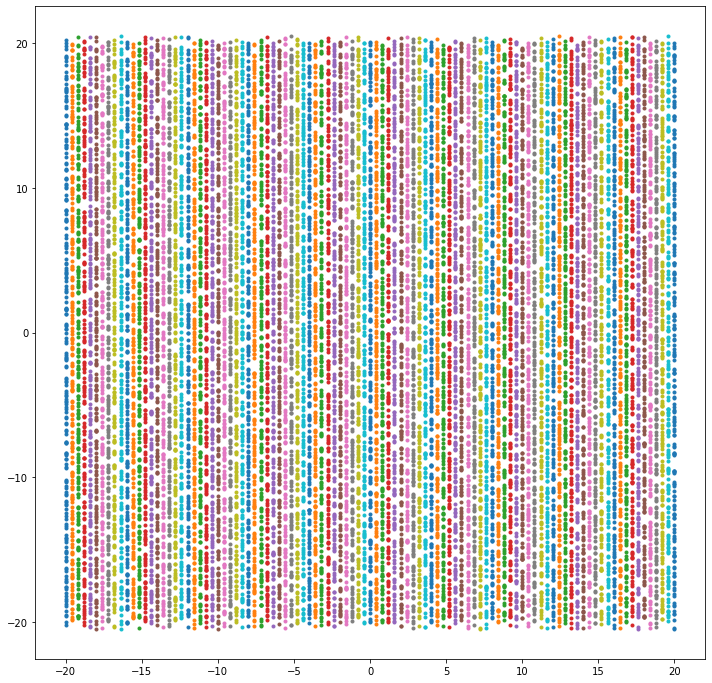

In [50]:
figure(figsize(12,12))
for ix in range(len(x)):
    plot(pp.x[ix,:],pp.z[ix,:],'.')

0.300 ms/step w/o particles
0.580 ms/step with particles


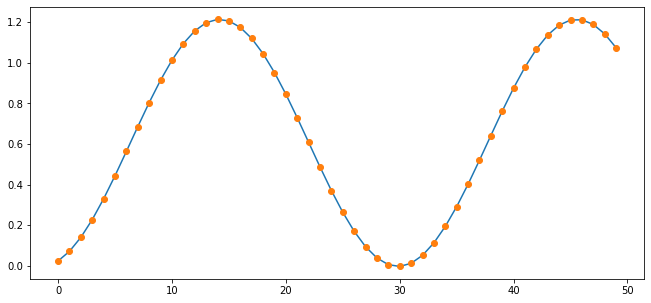

In [80]:
import time
figure(figsize=(11,5))
n=101
w=20
x=linspace(-w,w,n)
npc=2
pp=particles(x,x,npc,1)
By=arctan(x)*2.0/pi
dt=0.20
nt=50
for j in range(2):
    Ez=zeros(n)
    Jz=zeros(n)
    jz=[]
    ez=[]
    start=time.time()
    for i in range(nt):
        dEzdt=gradient(By,x)-Jz
        Ez+=dt*dEzdt
        ez.append(Ez[n//2])
        if j==1:
            pp.move(dt,Ez)
            Jz=pp.Jz
        else:
            dJzdt=Ez
            Jz+=dt*dJzdt
        # Avoid noise by keeping By(x) constant
        #dBydt=-gradient(Ez,x)
        #By+=dt*dBydt
        jz.append(Jz[n//2])
        #if i%20==0:
        #    plot(x,Ez)
    plot(jz,'-' if j==0 else 'o')
    s='with particles' if j else 'w/o particles'
    print('{:.3f} ms/step {}'.format((time.time()-start)*1e3/nt,s))

The results are essentially identical, with 1 particle per cell, but averaging over n cells in the z-direction.  Now it would be simple to reduce the number of cells in the z-direction, add some random thermal motion, and try different definitions of the electric current.